# Введение в регрессионный анализ

*Алла Тамбовцева*

## Практикум 3. Парная линейная регрессия. Введение в проверку гипотез

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

В файле `SBA_data.csv` (с прошлого семинара, если не сохранили – скачать [здесь](https://github.com/allatambov/PyReg26/blob/main/SBA_data.csv) или в письме) сохранены данные о кредитах, одобренных администрацией по делам малого бизнеса США в 2020 году (фискальный год). Основные переменные:

* `BorrName`: название компании-заемщика;
* `BorrStreet`, `BorrCity`, `BorrState`: адрес, город, штат компании-заемщика;
* `BankName`: название банка, выдающего кредит;
* `BorrStreet`, `BorrCity`, `BorrState`: адрес, город, штат банка;
* `GrossApproval`: сумма кредита, одобренная банком;
* `SBA`: сумма кредита, гарантированная администрацией по делам малого бизнеса (в долларах);
* `InitialInterestRate`: начальная ставка по кредиту;
* `TermInMonths`: срок кредита;
* `LoanOk`: количество одобренных или выплаченных кредитов за предыдущие 10 лет (2010-2019 годы).

Источник оригинальных данных – [Kaggle](https://www.kaggle.com/datasets/thedevastator/sba-loan-guarantee-data-1990-1999), данные были отфильтрованы и преобразованы для задач данного семинара.

## Постановка задачи и ключевые переменные

**Исследовательский вопрос.** Приводит ли увеличение количества одобренных или выплаченных кредитов за предыдущие годы (статусы *Commited* и *Paid in full*) к увеличению суммы кредита, гарантированной администрацией по делам малого бизнеса?

**Переменные.** Количество одобренных или выплаченных кредитов – столбец `LoanOk`, сумма кредита, гарантированная администрацией по делам малого бизнеса – столбец `SBA`. Для удобства интерпретации и сокращения разброса значений сумму кредита *необходимо перевести из долларов в тысячи долларов*.

### Задача 0

Загрузите данные из CSV-файла и сохраните их в датафрейм `df`. Добавьте столбец `SBA2` со значениями суммы кредита, гарантированной администрацией по делам малого бизнеса, измеренной *в тысячах долларов*. Постройте, используя `pandas`, диаграмму рассеивания между `LoanOk` и `SBA2`.

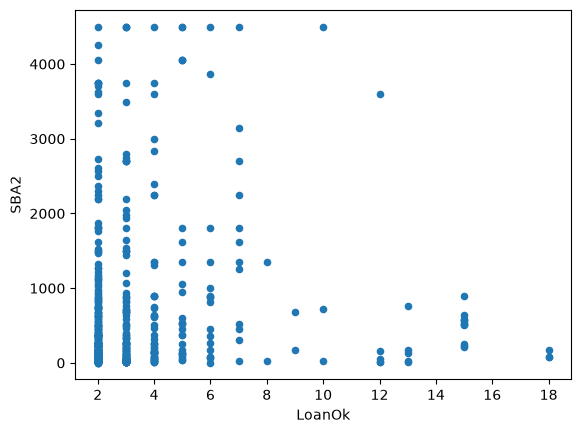

In [2]:
df = pd.read_csv("SBA_data.csv")
df["SBA2"] = df["SBA"] / 1000
df.plot.scatter(x = "LoanOk", y = "SBA2");

### Задача 1

Ниже приведен код для построения линейной модели $\widehat{SBA2}_i = \hat{b}_0 + \hat{b}_1 \times \text{LoanOk}_i$, она же `SBA2 ~ LoanOk`.

In [3]:
import statsmodels.formula.api as smf

In [4]:
# функция ols() резервирует место под результаты оценки модели,
# метод .fit() оценивает модель – вычисляет коэффициенты и все остальное,
# метод .summary() формирует выдачу (таблицу) с результатами

model = smf.ols("SBA2 ~ LoanOk", data = df).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   SBA2   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     5.063
Date:                Sat, 24 Oct 2026   Prob (F-statistic):             0.0248
Time:                        00:24:01   Log-Likelihood:                -5065.6
No. Observations:                 610   AIC:                         1.014e+04
Df Residuals:                     608   BIC:                         1.014e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    486.4707     63.434      7.669      0.000     361.894     611.047
LoanOk        33.8766     15.056      2.250      0.025       4.308      63.445
==============================================================================
Omnibus:                      309.948   Durbin-Watson:                   2.023
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1342.745
Skew:                           2.418   Prob(JB):                    2.67e-292
Kurtosis:                       8.425   Cond. No.                         6.98
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

* Запишите уравнение модели и проинтерпретируйте полученные результаты.
* Какое распределение имеет оценка коэффициента $\hat{b}_1$?
* Проверьте, используя разные подходы к проверке гипотез, можно ли считать коэффициент $b_1$ отличным от 0 на уровне доверия 95%.

> **Уравнение модели.** Смотрим на столбец `coef` во второй части выдачи. $\widehat{SBA2}_i = 486.47 + 33.88 \times \text{LoanOk}_i$. Согласно модели, компания с нулевым числом закрытых кредитов может ожидать, в среднем, гарантированную сумму кредита равную 486.47 тысячам долларов. При увеличении числа закрытых кредитов на 1, гарантированная сумма кредита, в среднем, увеличивается на 33.88 тысяч долларов. То есть, если сравнивать компании между собой, у тех, у которых в кредитной истории закрытых кредитов на один больше, сумма гарантированного кредита, в среднем, на 33.88 тысяч долларов выше.

> **Распределение оценок.** Оценка коэффициента $\hat{b}_1$ имеет распредение Стьюдента $t(\text{df} = n-2)$, здесь $n= 610$ (см. `No observations` в первой части выдачи), поэтому получаем $\hat{b}_1 \sim t(\text{df} = 608)$ (см. `Df Residuals`  в первой части выдачи). При таком большом числе степеней свободы распределение Стьюдента стремится к стандартному нормальному $N(0,1)$. А значит, 95% наиболее вероятных значений величины с таким распределением лежат в интервале от -2 до 2 (приблизительно, по правилу трех сигм).

>**Первый способ.** Смотрим на столбец `t` во второй части выдачи. Это наблюдаемые значения t-статистик, которые мы используем для проверки гипотезы $H_0: b_1 = 0$ против двусторонней альтернативы $H_1: b_1 \ne 0$. Для оценки этого коэффициента $t_{набл} = 2.25$: $$t_{набл} = \frac{33.8766}{15.056} = 2.250.$$ При условии, что $H_0$ верна, 95% значений лежат в интервале [-2; 2]. Здесь значение выходит за эти рамки, значит, данные свидетельствуют против $H_0$. Отвергаем $H_0$, коэффициент не равен 0, эффект `LoanOk` на `SBA2` статистически значим.

> **Второй способ.** Смотрим на столбец `P>|t|` во второй части выдачи. Это p-value: $$\text{P}(|t| > |t_{набл}|) = 2\text{P}(t > |t_{набл}|) = 2 \text{P}(t > 2.25) = 0.025.$$ Сравниваем p-value с уровнем значимости ($\alpha = 5$%), здесь p-value менее 0.05, «жизнеспособность» нулевой гипотезы с точки зрения данных лежит в пределах допустимой погрешности, а значит, нулевую гипотезу стоит отвергнуть, статистически значимый эффект есть.

> **Третий способ.** Смотрим на столбец `[0.025  0.975]` во второй части выдачи. Это границы 95%-ного доверительного интервала для коэффициентов регрессии. Если доверительный интервал включает 0, это означает, что с 95%-ной уверенностью коэффициент может равняться 0, а значит, на этом уровне доверия гипотезу отвергать не стоит. В нашем случае ситуация противоположная, для $b_1$ интервал [4.308, 63.445] не накрывает 0, значит, гипотезу отвергает, коэффициент не 0.

### Задача 2

Разделите данные на две подвыборки: компании, у которых сумма гарантированного кредита `SBA2` меньше 1000 (сохраните в датафрейм `one`), и компании, у которых сумма гарантированного кредита `SBA2` не менее 1000 (сохраните в датафрейм `two`). 

Оцените на каждой подвыборке модели $\widehat{SBA2}_i = \hat{b}_0 + \hat{b}_1 \times \text{LoanOk}_i$ и сравните результаты.

In [5]:
one = df[df["SBA2"] < 1000]
two = df[df["SBA2"] >= 1000]

In [6]:
# выведем через print() две выдачи одну за другой,
# summary() в print() даеют такое

model1 = smf.ols("SBA2 ~ LoanOk", data = one).fit()
print(model1.summary())

model2 = smf.ols("SBA2 ~ LoanOk", data = two).fit()
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                   SBA2   R-squared:                       0.024
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                     12.27
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           0.000500
Time:                        00:27:08   Log-Likelihood:                -3537.3
No. Observations:                 509   AIC:                             7079.
Df Residuals:                     507   BIC:                             7087.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    178.7904     17.332     10.316      0.0

**На первой подвыборке.** Уравнение модели: $\widehat{SBA2}_i = 178.79 + 14.28 \times \text{LoanOk}_i$. Коэффициент при `LoanOk` является статистически значимым на 95% уровне доверия:

* наблюдаемое значение t-статистики равно 3.503, выходит за границы [-2, 2];
* p-value меньше $\alpha=5$% (и даже $\alpha=1$%);
* 95% доверительный интервал [6.273, 22.293] не включает 0.

Раз коэффициент значим, его имеет смысл интерпретировать. При увеличении числа благополучно закрытых кредитов в кредитной истории компании на один, сумма кредита, гарантированная администрацией по делам малого бизнеса, увеличивается, в среднем, на 14.28 тысяч долларов.

**На второй подвыборке.** Уравнение модели: $\widehat{SBA2}_i = 2135.50 + 96.99 \times \text{LoanOk}_i$. Коэффициент при `LoanOk` НЕ является статистически значимым на 95% уровне доверия:

* наблюдаемое значение t-статистики равно 1.691, не выходит за границы [-2, 2];
* p-value больше $\alpha=5$%;
* 95% доверительный интервал [-16.799, 210.781] включает 0.

Раз коэффициент не значим, его нет большого смысла интерпретировать, с уверенностью 95% он не отличается от 0.

**Итого.** Если сравним результаты по двум моделям, получается, что на первой подвыборке оценка коэффициента при независимой переменной меньше (14.28 против 96.99), зато она является статистически значимой. Чтобы явно увидеть, почему все оказалось именно так, построим на диаграмме рассеивания две регрессионных прямых:

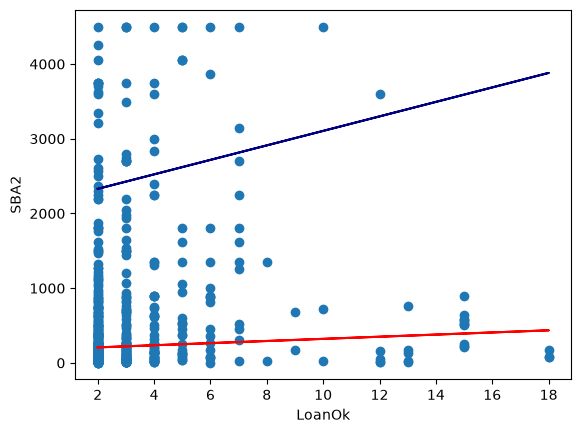

In [7]:
fig, ax = plt.subplots()
ax.scatter(df["LoanOk"], df["SBA2"]);
ax.plot(df["LoanOk"], 178.79 + 14.28 * df["LoanOk"], color = "red");
ax.plot(df["LoanOk"], 2135.50 + 96.99 * df["LoanOk"], color = "navy");
ax.set_xlabel("LoanOk");
ax.set_ylabel("SBA2");

Наклон красной прямой, действительно, более слабый, однако если рассматривать облако точек в этой части диаграммы, оно будет более «убедительным» с точки зрения линейной связи, точки лежат более скучено и при увеличении `LoanOk` можно увидеть увеличение `SBA2`. Синяя прямая наклонена сильнее, однако облако точек в этой части диаграммы более «размытое». Если убрать две точки, где `LoanOk` от 10 до 12, за счет которых у прямой и получается существенный угол наклона, в этой части диаграммы мы получим «квадрат» с точками, по которому вообще непонятно ни наличие связи, ни ее направление.